# Comparação das geometrias
Este notebook contém apenas leitura dos dados `.npz` e plotagem.

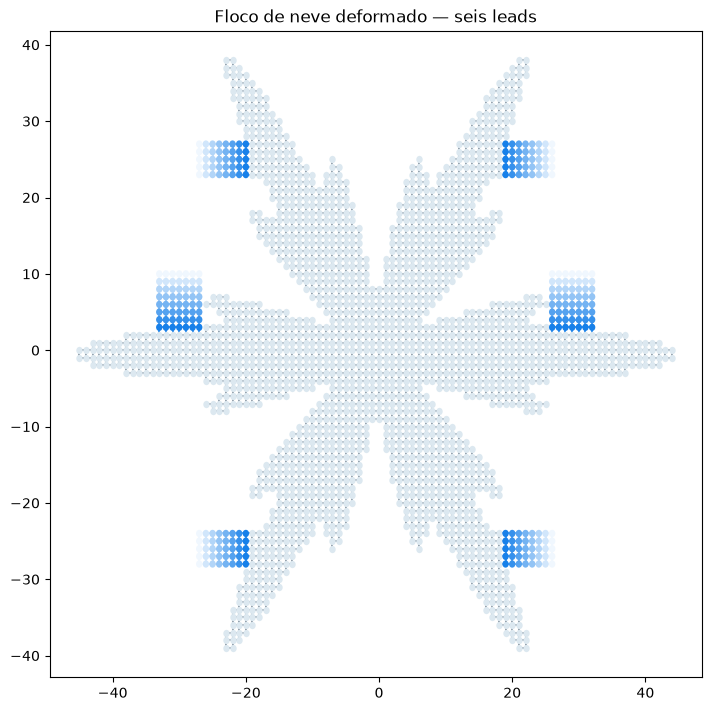

Figuras Kwant salvas em ../figures/geometry_comparison.png e ../figures/geometry_comparison.svg


In [20]:
from pathlib import Path

import kwant
import matplotlib.pyplot as plt
import numpy as np

DATA_PATH = Path('../data/geometries.npz')
FIGURES_DIR = Path('../figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

with np.load(DATA_PATH) as data:
    mask = data['mask']
    lattice_size = tuple(data['lattice_size'])
    terminals = data['terminals_lattice']
    normals = data['terminal_normals']

height, width = lattice_size
lattice = kwant.lattice.square(norbs=1)
x_offset, y_offset = width // 2, height // 2
cavity = kwant.Builder()

def in_cavity(pos):
    mx = int(pos[0] + x_offset)
    my = int(pos[1] + y_offset)
    return 0 <= mx < width and 0 <= my < height and bool(mask[my, mx])

cavity[lattice.shape(in_cavity, (0, 0))] = 0
cavity[lattice.neighbors()] = -1

for terminal, normal in zip(terminals, normals):
    x, y = map(int, terminal)
    nx, ny = int(normal[0]), int(normal[1])
    if abs(nx) >= abs(ny):
        nx, ny = (1 if nx >= 0 else -1, 0)
    else:
        nx, ny = (0, 1 if ny >= 0 else -1)
    tx, ty = -ny, nx
    interface = []
    for offset in range(-3, 4):
        mx, my = x + offset * tx, y + offset * ty
        if 0 <= mx < width and 0 <= my < height and mask[my, mx]:
            interface.append(lattice(mx - x_offset, my - y_offset))
    symmetry = kwant.TranslationalSymmetry((nx, ny))
    lead = kwant.Builder(symmetry)
    for site in interface:
        lead[site] = 0
    lead[lattice.neighbors()] = -1
    cavity.attach_lead(lead)

system = cavity.finalized()
fig, ax = plt.subplots(figsize=(7, 7), constrained_layout=True)
kwant.plot(system, ax=ax, lead_color='#0877e8', site_color='#dce8f0',
           hop_color='#7d8b99', hop_lw=0.24, num_lead_cells=8, site_size=0.48)
ax.set_title('Floco de neve deformado — seis leads')

png_path = FIGURES_DIR / 'geometry_comparison.png'
svg_path = FIGURES_DIR / 'geometry_comparison.svg'
fig.savefig(png_path, dpi=240, bbox_inches='tight')
fig.savefig(svg_path, bbox_inches='tight')
plt.show()
print(f'Figuras Kwant salvas em {png_path} e {svg_path}')